# Labelled pairs

What the labelled pairs of round 1 and round 2 look like.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

## Round 2 pool: kinds of pairs

About 20% random matches, 50% corner cases, 30% random non-matches.

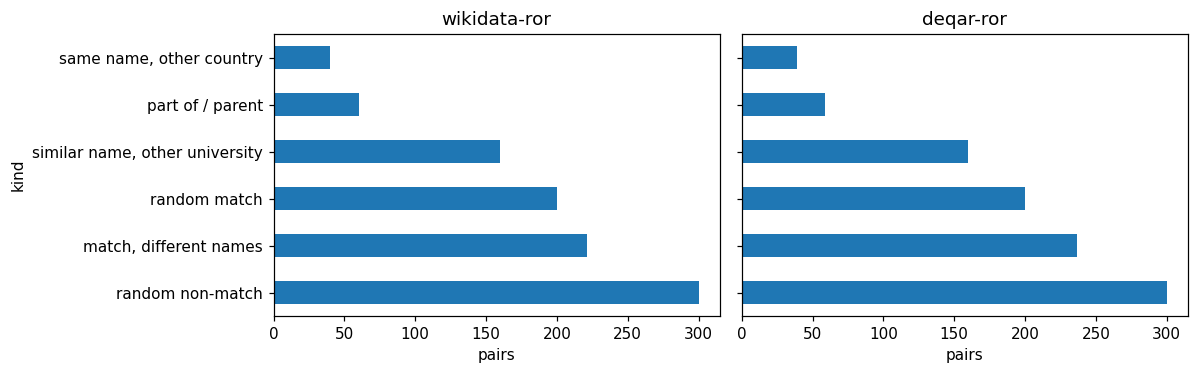

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, pair in zip(axes, ["wikidata_ror", "deqar_ror"]):
    pool = pd.read_csv(f"results/pool_{pair}.csv")
    pool["kind"].value_counts().plot.barh(ax=ax, color="tab:blue")
    ax.set_title(pair.replace("_", "-"))
    ax.set_xlabel("pairs")
plt.tight_layout()

## What the hand check changed

`flip` = label was wrong, `drop` = unclear, left out.

In [3]:
for pair in ["wikidata_ror", "deqar_ror"]:
    review = pd.read_csv(f"results/review_{pair}.csv")
    print(pair, review["decision"].value_counts().to_dict())
review.head(10)

wikidata_ror {'drop': 20, 'flip': 12}
deqar_ror {'flip': 26, 'drop': 10}


,id1,id2,decision,reason
0,deqar_DEQARINST7240,ror_05n2vpf20,flip,"wrong ID link, different institutions"
1,deqar_DEQARINST4788,ror_03pjs2912,flip,"wrong ID link, different institutions"
2,deqar_DEQARINST4455,ror_00n4c8134,flip,"wrong ID link, different institutions"
3,deqar_DEQARINST4473,ror_03pttjv50,flip,university linked to an archive
4,deqar_DEQARINST1624,ror_05450rm96,flip,"wrong ID link, different institutions"
5,deqar_DEQARINST4384,ror_03vqkag84,flip,"wrong ID link, different institutions"
6,deqar_DEQARINST7958,ror_01b8rza40,flip,university vs its agricultural center
7,deqar_DEQARINST4140,ror_039rg3x29,flip,"wrong ID link, different institutions"
8,deqar_DEQARINST5545,ror_0087qvf80,flip,"wrong ID link, different institutions"
9,deqar_DEQARINST5795,ror_03h1az021,flip,"wrong ID link, different institutions"


## Size of the splits

,round,pair,split,matches,non_matches,name
0,1,wikidata_ror,train,160,152,wikidata-ror\ntrain
1,1,wikidata_ror,validation,153,145,wikidata-ror\nvalidation
2,1,wikidata_ror,test,137,153,wikidata-ror\ntest
3,1,deqar_ror,train,158,132,deqar-ror\ntrain
4,1,deqar_ror,validation,152,156,deqar-ror\nvalidation
5,1,deqar_ror,test,140,162,deqar-ror\ntest
6,2,wikidata_ror,train,144,195,wikidata-ror\ntrain
7,2,wikidata_ror,validation,138,172,wikidata-ror\nvalidation
8,2,wikidata_ror,test,123,189,wikidata-ror\ntest
9,2,deqar_ror,train,151,196,deqar-ror\ntrain


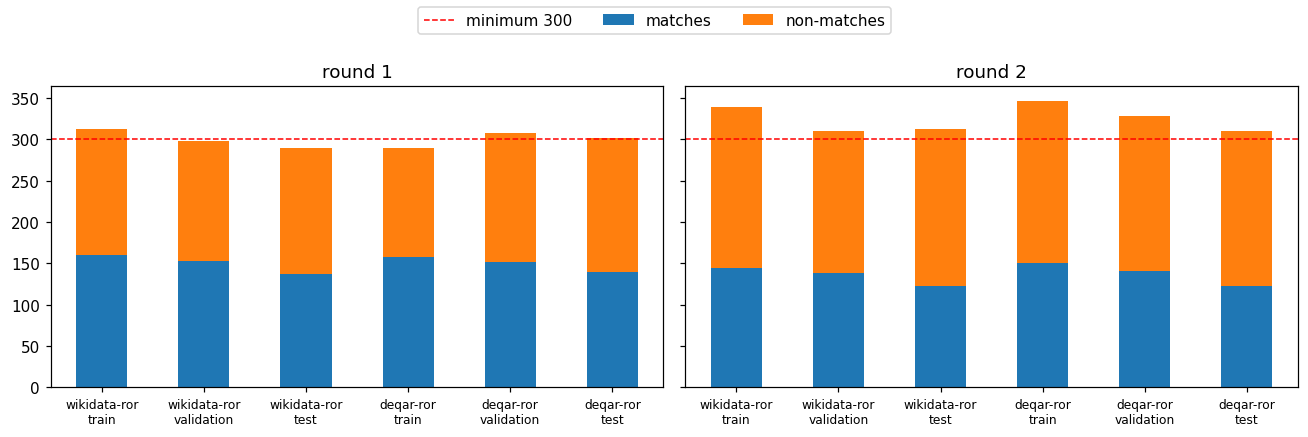

In [4]:
rows = []
for rnd in [1, 2]:
    for pair in ["wikidata_ror", "deqar_ror"]:
        for split in ["train", "validation", "test"]:
            df = pd.read_csv(f"results/round{rnd}/{pair}_{split}.csv")
            rows.append(dict(round=rnd, pair=pair, split=split, matches=df["label"].sum(),
                             non_matches=(~df["label"]).sum()))
sizes = pd.DataFrame(rows)
sizes["name"] = sizes["pair"].str.replace("_", "-") + "\n" + sizes["split"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, rnd in zip(axes, [1, 2]):
    part = sizes[sizes["round"] == rnd].set_index("name")[["matches", "non_matches"]]
    part.plot.bar(stacked=True, ax=ax, rot=0, legend=False)
    ax.axhline(300, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"round {rnd}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
fig.legend(["minimum 300", "matches", "non-matches"], loc="upper center", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.9))
sizes